# Transformer encoder for HAR — hyper-parameter-tuned run
**ICT-4442 · Model 4 (Transformer family) · K V Ananth Karantha**

Input: the shared processed dataset (`DL PROJ/processed/sequence.npz`, raw 9 channels × 128 steps).
Everything this notebook writes goes into the `DL PROJ/transformer/` folder.

### What changed relative to the interim baseline, and why
The baseline (92.84 % test accuracy, macro-F1 0.927) showed three problems: (1) confusion between the
three walking variants (8.2 %), (2) a large train→test gap (0.071 macro-F1) and (3) spiky validation
loss and growing over-confidence with a constant learning rate. Each mechanism below targets one of them:

| Mechanism | Targets | Rationale |
|---|---|---|
| **Convolutional stem** (2 × Conv1d k=5 + BN + GELU, stride 2) before the encoder | walking variants | Gives every token ≈ 0.2 s of local motion context (the CNN's strength — 1.4 % walking confusion) while attention still sees the whole window; halves the tokens (128→64) so attention is 4× cheaper. |
| **AdamW + linear warm-up + cosine decay** | spiky val loss | Warm-up avoids early instability of attention; decaying LR removes the late-epoch oscillation seen with constant 1e-3. |
| **EMA of weights** (evaluated + saved) | spiky val loss, generalization | Averaging the last ~500 steps of weights gives a flatter, better-generalizing solution and a much smoother validation curve. |
| **Label smoothing 0.1** | over-confidence (val loss drifting up) | Caps the logits, so the model cannot drive train loss to 0 by becoming over-confident. |
| **On-the-fly augmentation** (per-sensor intensity scaling, small 3-D rotation, jitter) in physical units | train→test gap, subject spread | Only 17 training subjects: augmentation simulates different movement intensity and phone orientation on the waist (the subject-10 problem). Fresh random draws every epoch > one fixed augmented copy. |
| **Dropout + stochastic depth, weight decay 0.05 (not on norms/biases/embeddings)** | overfitting | Standard Transformer regularisation for small datasets. |
| **Gradient clipping 1.0, mixed precision** | stability, speed | Same as the baseline. |
| **Early stopping on validation macro-F1 (patience 30, max 200 epochs)** | protocol | Restores the best EMA weights. |

Deliberately **not** used: Mixup/CutMix (mixing two different activities' signals produces physically
meaningless windows), class weighting (classes are nearly balanced), SGD (known to train Transformers
poorly; AdamW vs Adam is tested as an ablation instead), test-time augmentation (would multiply latency).

### Search strategy (all on validation macro-F1; the test set is used **once**, at the very end)
* **Stage A – architecture grid** (8 runs): stem {linear, conv} × d_model {64, 128} × layers {2, 4}.
* **Stage B – training-recipe grid** on the best architecture (12 runs): peak LR {5e-4, 1e-3} ×
  dropout {0.1, 0.2} × augmentation {none, light, full}.
* **Ablations** (analysis only, 5 runs): remove one mechanism at a time from the winner, plus an exact
  re-run of the interim baseline recipe, so the report can show what each mechanism contributes.

A full grid over every factor (≈ 300 runs) would not fit a Colab session; the two-stage grid searches the
factors that interact most strongly (architecture size, then LR × regularisation × augmentation) jointly.

**Colab disconnects are safe:** every finished run is saved to Drive; re-running the notebook skips
finished runs and continues where it stopped.

Runtime → Change runtime type → **T4 GPU**. Expected total time ≈ 1.5–2.5 h on a T4.

In [1]:
# ---------------------------------------------------------------- 0. Setup
import os, sys, json, time, copy, math, hashlib, itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
warnings.filterwarnings("ignore", category=UserWarning)

def find_project_root(start="/content/drive/MyDrive", name="dl proj"):
    if os.environ.get("HAR_PROJECT_ROOT"):
        return Path(os.environ["HAR_PROJECT_ROOT"])
    start = Path(start)
    cands = [start, *[p for p in start.iterdir() if p.is_dir()]]
    for p in cands:
        if p.name.lower().replace("_", " ") == name:
            return p
    for p in cands[1:]:
        try:
            for q in p.iterdir():
                if q.is_dir() and q.name.lower().replace("_", " ") == name:
                    return q
        except PermissionError:
            pass
    raise FileNotFoundError(f"No '{name}' folder under {start}; set PROJECT_ROOT manually.")

PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "processed"
OUT = next((p for p in PROJECT_ROOT.iterdir() if p.is_dir() and p.name.lower() in ("transformer", "transformers")),
           PROJECT_ROOT / "transformer")
RUNS_DIR, FIG_DIR, FINAL_DIR = OUT / "runs", OUT / "figures", OUT / "final_model"
for d in (RUNS_DIR, FIG_DIR, FINAL_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT_ROOT))
import har_common as hc

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
OWNER = "K V Ananth Karantha"
print("Project root:", PROJECT_ROOT, "\nOutputs     :", OUT, "\nDevice      :", DEVICE,
      torch.cuda.get_device_name(0) if DEVICE == "cuda" else "", "\nPyTorch     :", torch.__version__)
if DEVICE == "cpu":
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU (CPU will take many hours).")

Mounted at /content/drive
Project root: /content/drive/MyDrive/DL PROJ 
Outputs     : /content/drive/MyDrive/DL PROJ/Transformers 
Device      : cuda Tesla T4 
PyTorch     : 2.11.0+cu130


In [2]:
# ---------------------------------------------------------------- 1. Run settings
EPOCHS = 200                 # maximum epochs per run
PATIENCE = 30                # early stopping on validation macro-F1 (lets the cosine LR decay before stopping)
BATCH_SIZE = 64
QUICK_TEST = False           # True = 3 epochs per run, to check the notebook end-to-end in a few minutes
RUN_STAGE_B = True
RUN_ABLATIONS = True
MAX_CPU_LATENCY_MS = 5.0     # deployment budget from the interim plan; slower configs are not selected
                             # (set to None to disable)

# Defaults shared by every run; the grids below override some of them.
BASE_CFG = dict(
    # architecture
    stem="conv", patch=2, d_model=64, n_layers=2, head_dim=16, ff_mult=2,
    dropout=0.1, attn_dropout=0.1, drop_path=0.1, pool="cls",
    # optimisation
    optimizer="adamw", lr=1e-3, weight_decay=0.05, schedule="cosine", warmup_epochs=10, min_lr=1e-6,
    grad_clip=1.0, label_smoothing=0.1, ema=True, ema_decay=0.998,
    # data
    aug="light", batch_size=BATCH_SIZE, epochs=EPOCHS, patience=PATIENCE, seed=SEED,
)

STAGE_A_GRID = dict(stem=["linear", "conv"], d_model=[64, 128], n_layers=[2, 4])
STAGE_B_GRID = dict(lr=[5e-4, 1e-3], dropout=[0.1, 0.2], aug=["none", "light", "full"])

# The interim baseline recipe, reproduced exactly (for the before/after comparison).
BASELINE_CFG = dict(BASE_CFG, stem="linear", d_model=64, n_layers=2, ff_mult=2, dropout=0.1,
                    attn_dropout=0.1, drop_path=0.0, pool="cls", optimizer="adamw", lr=1e-3,
                    weight_decay=0.01, schedule="constant", warmup_epochs=0, label_smoothing=0.0,
                    ema=False, aug="none", patience=20)

if QUICK_TEST:                # smoke test: separate folder so it never mixes with the real search
    BASE_CFG.update(epochs=3, patience=3); BASELINE_CFG.update(epochs=3, patience=3)
    OUT = OUT / "_quick_test"
    RUNS_DIR, FIG_DIR, FINAL_DIR = OUT / "runs", OUT / "figures", OUT / "final_model"
    for d in (RUNS_DIR, FIG_DIR, FINAL_DIR):
        d.mkdir(parents=True, exist_ok=True)

In [3]:
# ---------------------------------------------------------------- 2. Data
data = hc.load_data("sequence", processed_dir=PROCESSED_DIR)
meta = data["meta"]
scaler = json.load(open(PROCESSED_DIR / "sequence_scaler.json"))
print("dataset_version:", meta["dataset_version"])
for s in ("train", "val", "test"):
    print(f"{s:5s}", data[f"X_{s}"].shape, np.bincount(data[f"y_{s}"]).tolist())

to_t = lambda a, dt=torch.float32: torch.as_tensor(a, dtype=dt, device=DEVICE)
Xtr, ytr = to_t(data["X_train"]), to_t(data["y_train"], torch.long)
Xva, yva = to_t(data["X_val"]), to_t(data["y_val"], torch.long)
# The test set stays on the CPU (numpy) until the single final evaluation.
CH_MEAN, CH_STD = to_t(scaler["mean"]), to_t(scaler["std"])

dataset_version: uci-har-1683f8492733
train (5974, 128, 9) [997, 866, 795, 1055, 1113, 1148]
val   (1378, 128, 9) [229, 207, 191, 231, 261, 259]
test  (2947, 128, 9) [496, 471, 420, 491, 532, 537]


In [4]:
# ---------------------------------------------------------------- 3. Augmentation (GPU, on the fly)
# Windows are stored z-scored; augmentations are applied in physical units (undo z-score, augment,
# redo z-score) so a rotation really is a rotation of the acceleration / angular-velocity vectors.
#   light : intensity scaling of body_acc & gyro (σ 0.1; gravity is left alone - it is always 1 g)
#           + Gaussian jitter (σ 0.03 in z-units)
#   full  : light + random 3-D rotation ≤ 10° applied identically to all three sensors
#           (the phone sitting at a slightly different angle on the waist)
def random_rotations(n, max_deg, device):
    axis = F.normalize(torch.randn(n, 3, device=device), dim=1)
    ang = (torch.rand(n, device=device) * 2 - 1) * math.radians(max_deg)
    K = torch.zeros(n, 3, 3, device=device)
    K[:, 0, 1], K[:, 0, 2], K[:, 1, 2] = -axis[:, 2], axis[:, 1], -axis[:, 0]
    K = K - K.transpose(1, 2)
    I = torch.eye(3, device=device).expand(n, 3, 3)
    s, c = torch.sin(ang)[:, None, None], torch.cos(ang)[:, None, None]
    return I + s * K + (1 - c) * (K @ K)                                   # Rodrigues' formula

def augment(xb, level):
    if level == "none":
        return xb
    raw = xb * CH_STD + CH_MEAN
    n = raw.shape[0]
    scale = 1 + 0.1 * torch.randn(n, 1, 2, device=xb.device)             # body_acc, gyro
    raw = torch.cat([raw[..., 0:3] * scale[..., 0:1], raw[..., 3:6] * scale[..., 1:2], raw[..., 6:9]], -1)
    if level == "full":
        R = random_rotations(n, 10.0, xb.device).transpose(1, 2)
        raw = torch.cat([raw[..., 0:3] @ R, raw[..., 3:6] @ R, raw[..., 6:9] @ R], -1)
    z = (raw - CH_MEAN) / CH_STD
    return z + 0.03 * torch.randn_like(z)

In [5]:
# ---------------------------------------------------------------- 4. Model
class DropPath(nn.Module):
    """Stochastic depth: randomly skips a residual branch per sample during training."""
    def __init__(self, p):
        super().__init__(); self.p = p
    def forward(self, x):
        if not self.training or self.p == 0:
            return x
        keep = torch.rand(x.shape[0], *([1] * (x.ndim - 1)), device=x.device) >= self.p
        return x * keep / (1 - self.p)

class EncoderBlock(nn.Module):
    """Pre-norm Transformer encoder layer (LN → MHSA → residual, LN → FFN → residual)."""
    def __init__(self, d, n_heads, ff_mult, dropout, attn_dropout, drop_path):
        super().__init__()
        self.h, self.attn_p = n_heads, attn_dropout
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.drop = nn.Dropout(dropout)
        self.ff = nn.Sequential(nn.Linear(d, ff_mult * d), nn.GELU(), nn.Dropout(dropout),
                                nn.Linear(ff_mult * d, d), nn.Dropout(dropout))
        self.dp = DropPath(drop_path)
        self.use_sdpa = True          # fused attention for speed; switched off for FLOP counting
        self.keep_attn = False        # store attention maps (for visualisation)

    def attention(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        p = self.attn_p if self.training else 0.0
        if self.use_sdpa and not self.keep_attn:
            o = F.scaled_dot_product_attention(q, k, v, dropout_p=p)
        else:
            a = (q @ k.transpose(-2, -1)) / math.sqrt(D // self.h)
            a = a.softmax(-1)
            if self.keep_attn:
                self.attn_map = a.detach()
            o = F.dropout(a, p, self.training) @ v
        return self.drop(self.proj(o.transpose(1, 2).reshape(B, T, D)))

    def forward(self, x):
        x = x + self.dp(self.attention(self.ln1(x)))
        return x + self.dp(self.ff(self.ln2(x)))

class HARTransformer(nn.Module):
    def __init__(self, stem="conv", patch=2, d_model=64, n_layers=2, head_dim=16, ff_mult=2,
                 dropout=0.1, attn_dropout=0.1, drop_path=0.1, pool="cls",
                 in_ch=9, seq_len=128, n_classes=6, **_):
        super().__init__()
        self.stem_type, self.pool = stem, pool
        if stem == "linear":                      # one token per 20 ms timestep (interim baseline)
            self.stem = nn.Linear(in_ch, d_model); n_tok = seq_len
        else:                                     # convolutional tokenizer
            self.stem = nn.Sequential(
                nn.Conv1d(in_ch, d_model, 5, padding=2), nn.BatchNorm1d(d_model), nn.GELU(),
                nn.Conv1d(d_model, d_model, 5, stride=patch, padding=2), nn.BatchNorm1d(d_model), nn.GELU())
            n_tok = (seq_len + 2 * 2 - 5) // patch + 1
        self.cls = nn.Parameter(torch.zeros(1, 1, d_model)) if pool == "cls" else None
        self.pos = nn.Parameter(torch.zeros(1, n_tok + (pool == "cls"), d_model))
        nn.init.trunc_normal_(self.pos, std=0.02)
        if self.cls is not None:
            nn.init.trunc_normal_(self.cls, std=0.02)
        self.emb_drop = nn.Dropout(dropout)
        dprs = [drop_path * i / max(n_layers - 1, 1) for i in range(n_layers)]   # linearly increasing
        self.blocks = nn.ModuleList([EncoderBlock(d_model, max(d_model // head_dim, 1), ff_mult, dropout,
                                                  attn_dropout, dp) for dp in dprs])
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, n_classes)
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, x):                           # x: (B, 128, 9)
        x = self.stem(x) if self.stem_type == "linear" else self.stem(x.transpose(1, 2)).transpose(1, 2)
        if self.cls is not None:
            x = torch.cat([self.cls.expand(x.shape[0], -1, -1), x], 1)
        x = self.emb_drop(x + self.pos)
        for blk in self.blocks:
            x = blk(x)
        x = self.norm(x)
        return self.head(x[:, 0] if self.pool == "cls" else x.mean(1))

    def set_sdpa(self, flag):
        for b in self.blocks:
            b.use_sdpa = flag

In [6]:
# ---------------------------------------------------------------- 5. Training utilities
class EMA:
    """Exponential moving average of all weights and buffers (evaluated and checkpointed)."""
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay, self.n = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))          # short warm-up of the average
        for e, m in zip(self.module.state_dict().values(), model.state_dict().values()):
            if e.dtype.is_floating_point:
                e.mul_(d).add_(m.detach(), alpha=1 - d)
            else:
                e.copy_(m)

def param_groups(model, wd):
    decay, no_decay = [], []
    for n, p in model.named_parameters():
        (no_decay if p.ndim <= 1 or n in ("pos", "cls") else decay).append(p)
    return [{"params": decay, "weight_decay": wd}, {"params": no_decay, "weight_decay": 0.0}]

def make_optimizer(model, cfg):
    if cfg["optimizer"] == "adamw":
        return torch.optim.AdamW(param_groups(model, cfg["weight_decay"]), lr=cfg["lr"], betas=(0.9, 0.999))
    if cfg["optimizer"] == "adam":                 # plain Adam, no weight decay (ablation)
        return torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    raise ValueError(cfg["optimizer"])

def make_lr_lambda(cfg, steps_per_epoch):
    warm = cfg["warmup_epochs"] * steps_per_epoch
    total = cfg["epochs"] * steps_per_epoch
    floor = cfg["min_lr"] / cfg["lr"]
    def f(step):
        if cfg["schedule"] == "constant":
            return 1.0
        if step < warm:
            return (step + 1) / warm
        t = min((step - warm) / max(total - warm, 1), 1.0)
        return floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * t))
    return f

@torch.no_grad()
def predict_proba(model, X, batch=1024):
    """Softmax probabilities for a numpy array or tensor X (N, 128, 9)."""
    model.eval()
    dev = next(model.parameters()).device
    out = []
    for i in range(0, len(X), batch):
        xb = torch.as_tensor(X[i:i + batch], dtype=torch.float32, device=dev)
        out.append(F.softmax(model(xb).float(), -1).cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def eval_split(model, X, y):
    p = predict_proba(model, X)
    yt = y.cpu().numpy() if torch.is_tensor(y) else y
    from sklearn.metrics import f1_score
    pred = p.argmax(1)
    loss = float(-np.log(np.clip(p[np.arange(len(yt)), yt], 1e-12, None)).mean())  # plain CE
    return loss, float((pred == yt).mean()), float(f1_score(yt, pred, average="macro")), p

def roughness(series):
    """Mean absolute epoch-to-epoch change - lower = smoother curve."""
    s = np.asarray(series, dtype=float)
    return float(np.abs(np.diff(s)).mean()) if len(s) > 1 else float("nan")

def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")

def cfg_id(cfg):
    return hashlib.md5(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:8]

In [7]:
# ---------------------------------------------------------------- 6. One training run
def train_run(name, cfg, verbose=True):
    """Train one configuration (or load it if it already finished). Returns a summary dict."""
    run_dir = RUNS_DIR / f"{name}_{cfg_id(cfg)}"
    if (run_dir / "result.json").exists():
        res = json.load(open(run_dir / "result.json"))
        print(f"[skip] {name}: already done (val macro-F1 {res['val_macro_f1']:.4f})")
        return res
    run_dir.mkdir(parents=True, exist_ok=True)
    json.dump(cfg, open(run_dir / "config.json", "w"), indent=2)

    torch.manual_seed(cfg["seed"]); np.random.seed(cfg["seed"])
    if DEVICE == "cuda":
        torch.cuda.manual_seed_all(cfg["seed"]); torch.cuda.reset_peak_memory_stats()
    torch.backends.cudnn.benchmark = False

    model = HARTransformer(**cfg).to(DEVICE)
    ema = EMA(model, cfg["ema_decay"]) if cfg["ema"] else None
    opt = make_optimizer(model, cfg)
    n, bs = len(Xtr), cfg["batch_size"]
    steps = n // bs                                         # drop_last (BatchNorm in the stem)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, make_lr_lambda(cfg, steps))
    scaler_amp = make_scaler()
    gen = torch.Generator(device="cpu").manual_seed(cfg["seed"])

    hist, best = [], dict(f1=-1, loss=1e9, epoch=0, state=None)
    t0 = time.time()
    for epoch in range(1, cfg["epochs"] + 1):
        te = time.time()
        model.train()
        perm = torch.randperm(n, generator=gen).to(DEVICE)
        run_loss = 0.0
        for i in range(steps):
            idx = perm[i * bs:(i + 1) * bs]
            xb, yb = augment(Xtr[idx], cfg["aug"]), ytr[idx]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
                loss = F.cross_entropy(model(xb), yb, label_smoothing=cfg["label_smoothing"])
            opt.zero_grad(set_to_none=True)
            scaler_amp.scale(loss).backward()
            scaler_amp.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            scaler_amp.step(opt); scaler_amp.update(); sched.step()
            if ema:
                ema.update(model)
            run_loss += loss.item()
        ev = ema.module if ema else model
        tr_loss, tr_acc, tr_f1, _ = eval_split(ev, Xtr, ytr)        # clean (no aug / dropout / smoothing)
        va_loss, va_acc, va_f1, _ = eval_split(ev, Xva, yva)
        hist.append(dict(epoch=epoch, train_loss_optimised=run_loss / steps, train_loss=tr_loss,
                         train_acc=tr_acc, train_macro_f1=tr_f1, val_loss=va_loss, val_acc=va_acc,
                         val_macro_f1=va_f1, lr=opt.param_groups[0]["lr"], epoch_time_s=time.time() - te))
        improved = va_f1 > best["f1"] + 1e-4 or (abs(va_f1 - best["f1"]) <= 1e-4 and va_loss < best["loss"])
        if improved:
            best = dict(f1=va_f1, loss=va_loss, epoch=epoch, acc=va_acc,
                        state={k: v.detach().cpu().clone() for k, v in ev.state_dict().items()})
        if verbose and (epoch % 10 == 0 or epoch == 1 or improved and epoch > 10):
            print(f"  {name} ep {epoch:3d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} "
                  f"acc {va_acc:.4f} F1 {va_f1:.4f} | lr {hist[-1]['lr']:.2e}{'  *' if improved else ''}")
        if epoch - best["epoch"] >= cfg["patience"]:
            break
    train_time = time.time() - t0
    peak_mem = torch.cuda.max_memory_allocated() / 2 ** 20 if DEVICE == "cuda" else float("nan")

    torch.save({"state_dict": best["state"], "config": cfg}, run_dir / "best.pt")
    h = pd.DataFrame(hist); h.to_csv(run_dir / "history.csv", index=False)
    model.load_state_dict(best["state"])
    lat = hc.measure_latency(model, (1, 128, 9), "cpu", n_warmup=20, n_runs=100)
    res = dict(name=name, run_id=cfg_id(cfg), run_dir=str(run_dir), **{f"cfg_{k}": v for k, v in cfg.items()},
               val_macro_f1=best["f1"], val_acc=best["acc"], val_loss_at_best=best["loss"],
               best_epoch=best["epoch"], epochs_trained=len(h), train_time_s=train_time,
               time_per_epoch_s=train_time / len(h), peak_gpu_mem_mb=peak_mem,
               params_total=hc.count_params(model), latency_ms_cpu_b1=lat,
               train_macro_f1_at_best=float(h.loc[best["epoch"] - 1, "train_macro_f1"]),
               val_loss_roughness=roughness(h["val_loss"]), val_f1_roughness=roughness(h["val_macro_f1"]),
               min_val_loss=float(h["val_loss"].min()))
    json.dump(res, open(run_dir / "result.json", "w"), indent=2)
    plot_history(h, best["epoch"], f"{name}  (val macro-F1 {best['f1']:.4f})", run_dir / "curves.png", show=False)
    print(f"[done] {name}: val macro-F1 {best['f1']:.4f} acc {best['acc']:.4f} @ epoch {best['epoch']} "
          f"({len(h)} epochs, {train_time:.0f}s, {res['params_total']:,} params, CPU {lat:.2f} ms)")
    return res

def plot_history(h, best_epoch, title, path=None, show=True):
    fig, ax = plt.subplots(1, 4, figsize=(22, 4.6))
    ax[0].plot(h.epoch, h.train_loss, label="train (clean)")
    ax[0].plot(h.epoch, h.val_loss, label="validation")
    ax[0].plot(h.epoch, h.train_loss_optimised, ":", alpha=.7, label="train (as optimised: aug + LS)")
    ax[0].set_title("Cross-entropy loss"); ax[0].set_yscale("log")
    ax[1].plot(h.epoch, h.train_acc, label="train"); ax[1].plot(h.epoch, h.val_acc, label="validation")
    ax[1].set_title("Accuracy")
    ax[2].plot(h.epoch, h.train_macro_f1, label="train"); ax[2].plot(h.epoch, h.val_macro_f1, label="validation")
    ax[2].set_title("Macro-F1")
    ax[3].plot(h.epoch, h.lr, color="tab:purple"); ax[3].set_title("Learning rate"); ax[3].set_yscale("log")
    for a in ax:
        a.axvline(best_epoch, ls="--", c="gray", lw=1); a.set_xlabel("epoch"); a.grid(alpha=.3)
    for a in ax[:3]:
        a.legend()
    fig.suptitle(title); fig.tight_layout()
    if path:
        fig.savefig(path, dpi=130, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)

def record(res, stage):
    """Append/refresh one row in grid_search_results.csv (every hyper-parameter + val metrics)."""
    path = OUT / "grid_search_results.csv"
    row = pd.DataFrame([dict(stage=stage, **res)])
    if path.exists():
        old = pd.read_csv(path)
        old = old[~((old["run_id"] == res["run_id"]) & (old["name"] == res["name"]))]
        row = pd.concat([old, row], ignore_index=True)
    row.to_csv(path, index=False)

def grid(base, space, prefix):
    keys = list(space)
    for vals in itertools.product(*space.values()):
        cfg = dict(base, **dict(zip(keys, vals)))
        short = dict(stem="", d_model="d", n_layers="L", lr="lr", dropout="do", aug="aug")
        tag = "_".join(f"{short.get(k, k)}{v:g}" if isinstance(v, float) else f"{short.get(k, k)}{v}"
                       for k, v in zip(keys, vals))
        yield f"{prefix}_{tag}", cfg

def pick_best(results):
    ok = [r for r in results if MAX_CPU_LATENCY_MS is None or r["latency_ms_cpu_b1"] <= MAX_CPU_LATENCY_MS]
    if not ok:
        print("No run met the latency budget - selecting among all runs.")
        ok = results
    return max(ok, key=lambda r: (round(r["val_macro_f1"], 4), -r["val_loss_at_best"]))

def cfg_from(res):
    return {k[4:]: v for k, v in res.items() if k.startswith("cfg_")}

In [8]:
# ---------------------------------------------------------------- 7. Stage A - architecture grid
stage_a = []
for name, cfg in grid(BASE_CFG, STAGE_A_GRID, "A"):
    r = train_run(name, cfg); record(r, "A_architecture"); stage_a.append(r)
best_a = pick_best(stage_a)
print("\nStage A winner:", best_a["name"], f"val macro-F1 {best_a['val_macro_f1']:.4f}")
pd.DataFrame(stage_a)[["name", "cfg_stem", "cfg_d_model", "cfg_n_layers", "params_total", "val_macro_f1",
                       "val_acc", "best_epoch", "epochs_trained", "latency_ms_cpu_b1", "val_loss_roughness"]] \
    .sort_values("val_macro_f1", ascending=False)

  A_linear_d64_L2 ep   1 | train loss 1.1497 acc 0.7116 | val loss 1.1455 acc 0.7141 F1 0.6427 | lr 1.01e-04  *
  A_linear_d64_L2 ep  10 | train loss 0.1810 acc 0.9469 | val loss 0.2296 acc 0.9311 F1 0.9306 | lr 1.00e-03  *
  A_linear_d64_L2 ep  20 | train loss 0.1693 acc 0.9556 | val loss 0.2336 acc 0.9282 F1 0.9283 | lr 9.93e-04
  A_linear_d64_L2 ep  28 | train loss 0.1519 acc 0.9653 | val loss 0.2227 acc 0.9303 F1 0.9307 | lr 9.78e-04  *
  A_linear_d64_L2 ep  30 | train loss 0.1455 acc 0.9695 | val loss 0.2292 acc 0.9274 F1 0.9276 | lr 9.73e-04
  A_linear_d64_L2 ep  31 | train loss 0.1434 acc 0.9699 | val loss 0.2255 acc 0.9325 F1 0.9329 | lr 9.70e-04  *
  A_linear_d64_L2 ep  33 | train loss 0.1378 acc 0.9702 | val loss 0.2196 acc 0.9325 F1 0.9330 | lr 9.64e-04  *
  A_linear_d64_L2 ep  36 | train loss 0.1298 acc 0.9729 | val loss 0.2283 acc 0.9347 F1 0.9354 | lr 9.55e-04  *
  A_linear_d64_L2 ep  40 | train loss 0.1248 acc 0.9747 | val loss 0.2397 acc 0.9361 F1 0.9368 | lr 9.40e-04  

,name,cfg_stem,cfg_d_model,cfg_n_layers,params_total,val_macro_f1,val_acc,best_epoch,epochs_trained,latency_ms_cpu_b1,val_loss_roughness
4,A_conv_d64_L2,conv,64,2,95430,0.979565,0.978229,68,98,1.329323,0.011045
5,A_conv_d64_L4,conv,64,4,162374,0.976796,0.975327,70,100,2.644527,0.009991
6,A_conv_d128_L2,conv,128,2,362886,0.974030,0.972424,32,62,2.468968,0.005392
7,A_conv_d128_L4,conv,128,4,627846,0.973356,0.971698,37,67,4.260175,0.004417
3,A_linear_d128_L4,linear,128,4,548870,0.953803,0.952104,24,54,4.594723,0.010898
1,A_linear_d64_L4,linear,64,4,143366,0.953529,0.951379,14,44,3.252186,0.022887
2,A_linear_d128_L2,linear,128,2,283910,0.951556,0.950653,26,56,2.315345,0.011597
0,A_linear_d64_L2,linear,64,2,76422,0.938654,0.937591,42,72,1.374952,0.015763


In [9]:
# ---------------------------------------------------------------- 8. Stage B - training-recipe grid
stage_b = []
if RUN_STAGE_B:
    arch = {k: cfg_from(best_a)[k] for k in STAGE_A_GRID}
    for name, cfg in grid(dict(BASE_CFG, **arch), STAGE_B_GRID, "B"):
        r = train_run(name, cfg); record(r, "B_recipe"); stage_b.append(r)
best = pick_best(stage_a + stage_b)
BEST_CFG = cfg_from(best)
print("\nSELECTED CONFIGURATION:", best["name"], f"(val macro-F1 {best['val_macro_f1']:.4f})")
print(json.dumps(BEST_CFG, indent=2))
json.dump({"selected_run": best["name"], "config": BEST_CFG, "val_macro_f1": best["val_macro_f1"]},
          open(OUT / "best_config.json", "w"), indent=2)
if stage_b:
    display_cols = ["name", "cfg_lr", "cfg_dropout", "cfg_aug", "val_macro_f1", "val_acc", "best_epoch",
                    "epochs_trained", "val_loss_roughness"]
    print(pd.DataFrame(stage_b)[display_cols].sort_values("val_macro_f1", ascending=False).to_string(index=False))

  B_lr0.0005_do0.1_augnone ep   1 | train loss 1.2329 acc 0.6813 | val loss 1.2207 acc 0.6836 F1 0.6025 | lr 5.05e-05  *
  B_lr0.0005_do0.1_augnone ep  10 | train loss 0.1748 acc 0.9515 | val loss 0.1756 acc 0.9543 F1 0.9570 | lr 5.00e-04
  B_lr0.0005_do0.1_augnone ep  11 | train loss 0.1713 acc 0.9585 | val loss 0.1693 acc 0.9557 F1 0.9584 | lr 5.00e-04  *
  B_lr0.0005_do0.1_augnone ep  15 | train loss 0.1516 acc 0.9705 | val loss 0.1700 acc 0.9579 F1 0.9600 | lr 4.99e-04  *
  B_lr0.0005_do0.1_augnone ep  16 | train loss 0.1452 acc 0.9729 | val loss 0.1634 acc 0.9601 F1 0.9623 | lr 4.99e-04  *
  B_lr0.0005_do0.1_augnone ep  17 | train loss 0.1401 acc 0.9749 | val loss 0.1629 acc 0.9615 F1 0.9635 | lr 4.98e-04  *
  B_lr0.0005_do0.1_augnone ep  18 | train loss 0.1354 acc 0.9767 | val loss 0.1582 acc 0.9637 F1 0.9656 | lr 4.98e-04  *
  B_lr0.0005_do0.1_augnone ep  19 | train loss 0.1317 acc 0.9786 | val loss 0.1556 acc 0.9659 F1 0.9679 | lr 4.97e-04  *
  B_lr0.0005_do0.1_augnone ep  20 |

In [10]:
# ---------------------------------------------------------------- 9. Ablations (validation only)
ablation = []
if RUN_ABLATIONS:
    variants = {
        "abl_interim_baseline_recipe": BASELINE_CFG,
        "abl_no_ema": dict(BEST_CFG, ema=False),
        "abl_no_label_smoothing": dict(BEST_CFG, label_smoothing=0.0),
        "abl_constant_lr": dict(BEST_CFG, schedule="constant", warmup_epochs=0),
        "abl_adam_instead_of_adamw": dict(BEST_CFG, optimizer="adam"),
    }
    for name, cfg in variants.items():
        r = train_run(name, cfg); record(r, "ablation"); ablation.append(r)
    abl = pd.DataFrame([dict(best, name="SELECTED (all mechanisms)")] + ablation)
    abl = abl[["name", "val_macro_f1", "val_acc", "min_val_loss", "val_loss_roughness", "best_epoch",
               "epochs_trained", "train_macro_f1_at_best"]]
    abl.to_csv(OUT / "ablation_results.csv", index=False)
    print(abl.to_string(index=False))

  abl_interim_baseline_recipe ep   1 | train loss 0.3126 acc 0.8977 | val loss 0.3568 acc 0.8578 F1 0.8553 | lr 1.00e-03  *
  abl_interim_baseline_recipe ep  10 | train loss 0.1309 acc 0.9491 | val loss 0.3103 acc 0.9245 F1 0.9190 | lr 1.00e-03
  abl_interim_baseline_recipe ep  17 | train loss 0.0938 acc 0.9603 | val loss 0.2155 acc 0.9332 F1 0.9335 | lr 1.00e-03  *
  abl_interim_baseline_recipe ep  18 | train loss 0.0827 acc 0.9603 | val loss 0.1439 acc 0.9536 F1 0.9546 | lr 1.00e-03  *
  abl_interim_baseline_recipe ep  20 | train loss 0.0754 acc 0.9677 | val loss 0.1481 acc 0.9318 F1 0.9327 | lr 1.00e-03
  abl_interim_baseline_recipe ep  22 | train loss 0.0738 acc 0.9695 | val loss 0.1598 acc 0.9579 F1 0.9569 | lr 1.00e-03  *
  abl_interim_baseline_recipe ep  30 | train loss 0.0612 acc 0.9769 | val loss 0.1944 acc 0.9361 F1 0.9363 | lr 1.00e-03
  abl_interim_baseline_recipe ep  40 | train loss 0.0323 acc 0.9868 | val loss 0.2169 acc 0.9361 F1 0.9389 | lr 1.00e-03
[done] abl_interim_b

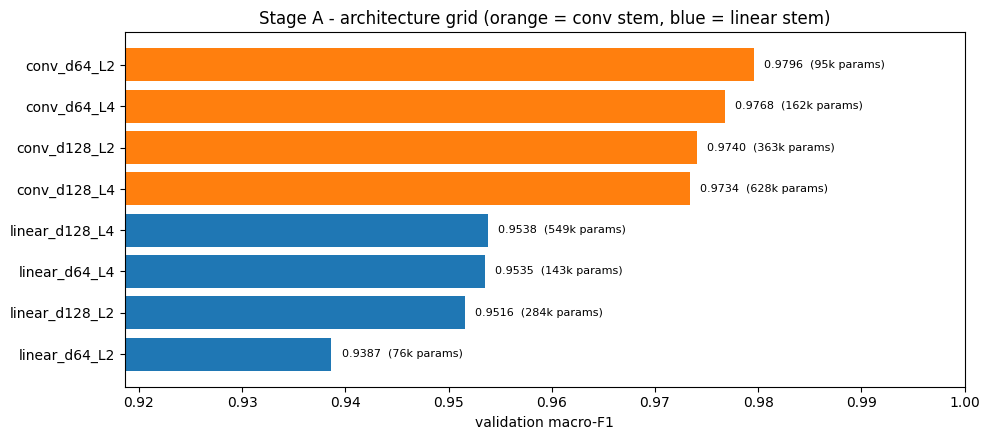

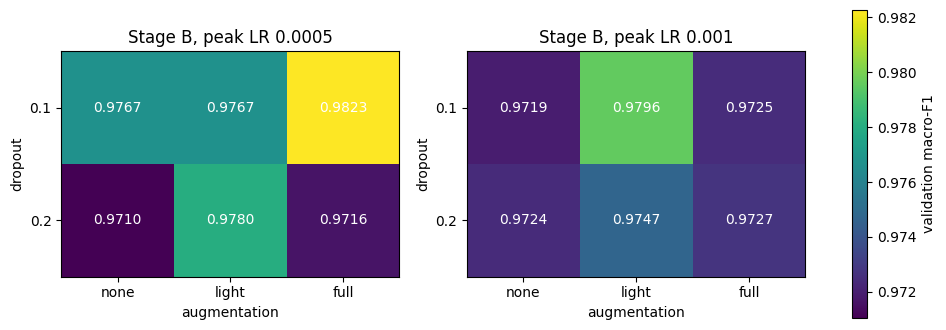

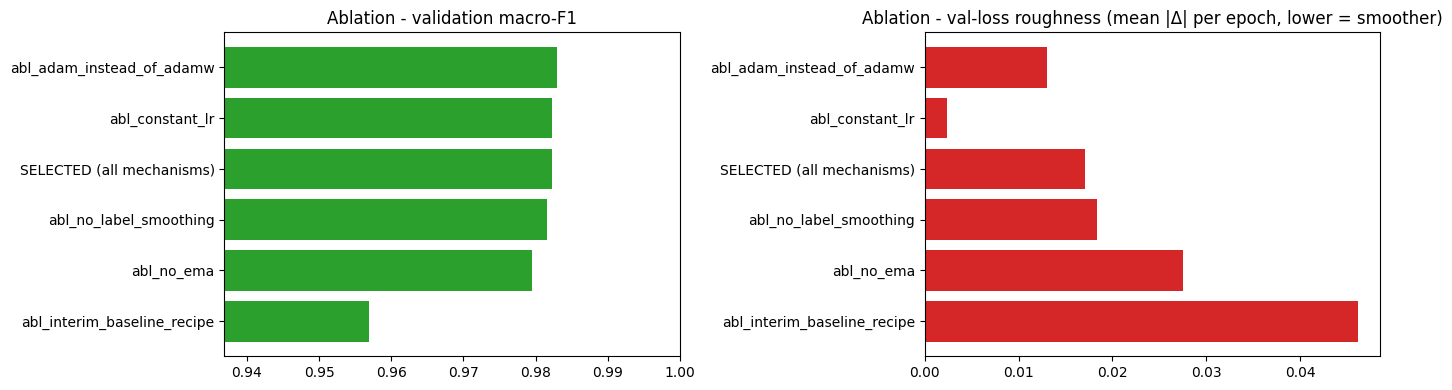

In [11]:
# ---------------------------------------------------------------- 10. Search figures
gs = pd.read_csv(OUT / "grid_search_results.csv")

fig, ax = plt.subplots(figsize=(10, 4.5))
a = gs[gs.stage == "A_architecture"].sort_values("val_macro_f1")
ax.barh(a["name"].str.replace("A_", ""), a["val_macro_f1"], color=["tab:orange" if s == "conv" else "tab:blue"
                                                                    for s in a["cfg_stem"]])
ax.set_xlim(a["val_macro_f1"].min() - 0.02, 1.0); ax.set_xlabel("validation macro-F1")
ax.set_title("Stage A - architecture grid (orange = conv stem, blue = linear stem)")
for y, (v, p) in enumerate(zip(a["val_macro_f1"], a["params_total"])):
    ax.text(v + 0.001, y, f"{v:.4f}  ({p/1e3:.0f}k params)", va="center", fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "grid_stageA_architecture.png", dpi=150); plt.show()

b = gs[gs.stage == "B_recipe"]
if len(b):
    fig, axes = plt.subplots(1, b["cfg_lr"].nunique(), figsize=(6 * b["cfg_lr"].nunique(), 4))
    axes = np.atleast_1d(axes)
    for ax, (lr_, sub) in zip(axes, b.groupby("cfg_lr")):
        piv = sub.pivot_table(index="cfg_dropout", columns="cfg_aug", values="val_macro_f1")
        piv = piv[[c for c in ["none", "light", "full"] if c in piv.columns]]
        im = ax.imshow(piv.values, cmap="viridis", vmin=b.val_macro_f1.min(), vmax=b.val_macro_f1.max())
        ax.set_xticks(range(piv.shape[1]), piv.columns); ax.set_yticks(range(piv.shape[0]), piv.index)
        ax.set_xlabel("augmentation"); ax.set_ylabel("dropout"); ax.set_title(f"Stage B, peak LR {lr_:g}")
        for i in range(piv.shape[0]):
            for j in range(piv.shape[1]):
                ax.text(j, i, f"{piv.values[i, j]:.4f}", ha="center", va="center", color="w")
    fig.colorbar(im, ax=axes.tolist(), label="validation macro-F1")
    fig.savefig(FIG_DIR / "grid_stageB_recipe.png", dpi=150, bbox_inches="tight"); plt.show()

if ablation:
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    abl_s = abl.sort_values("val_macro_f1")
    ax[0].barh(abl_s["name"], abl_s["val_macro_f1"], color="tab:green")
    ax[0].set_xlim(abl_s["val_macro_f1"].min() - 0.02, 1); ax[0].set_title("Ablation - validation macro-F1")
    ax[1].barh(abl_s["name"], abl_s["val_loss_roughness"], color="tab:red")
    ax[1].set_title("Ablation - val-loss roughness (mean |Δ| per epoch, lower = smoother)")
    fig.tight_layout(); fig.savefig(FIG_DIR / "ablation.png", dpi=150); plt.show()

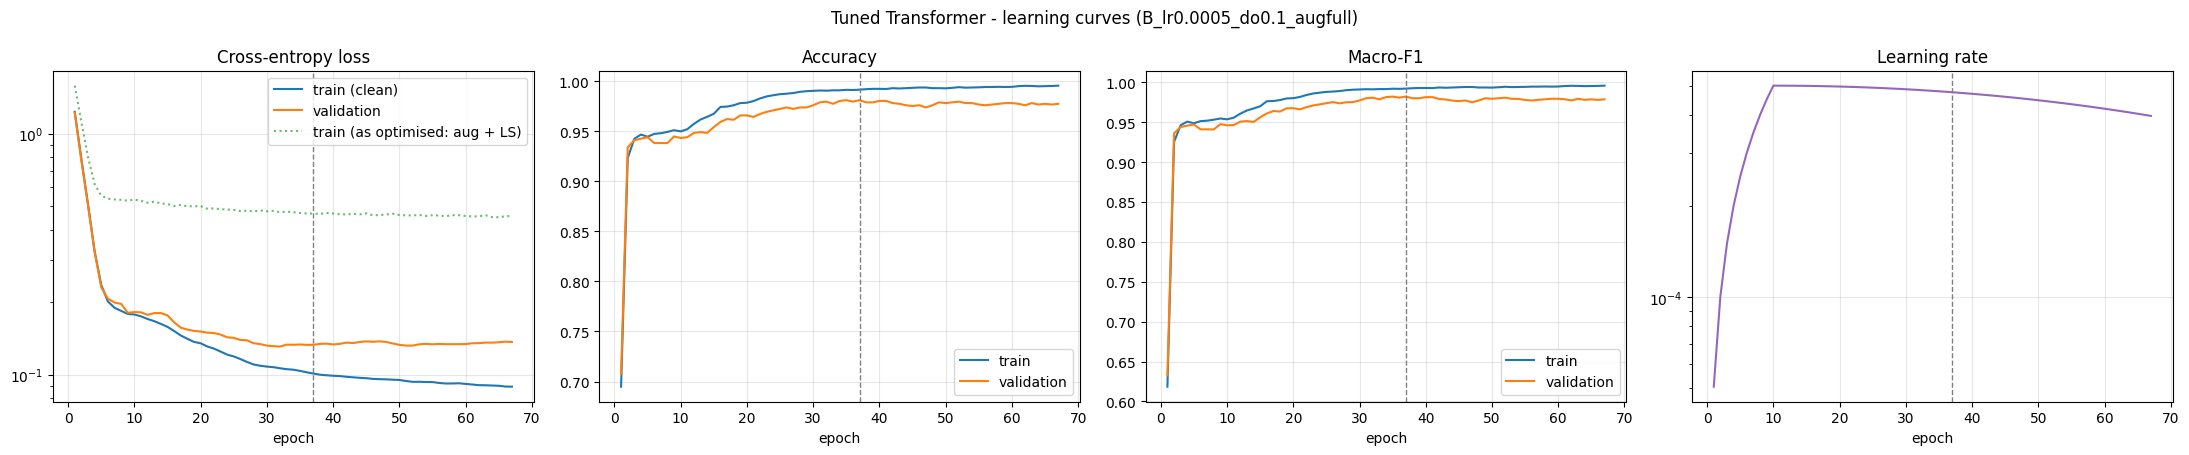

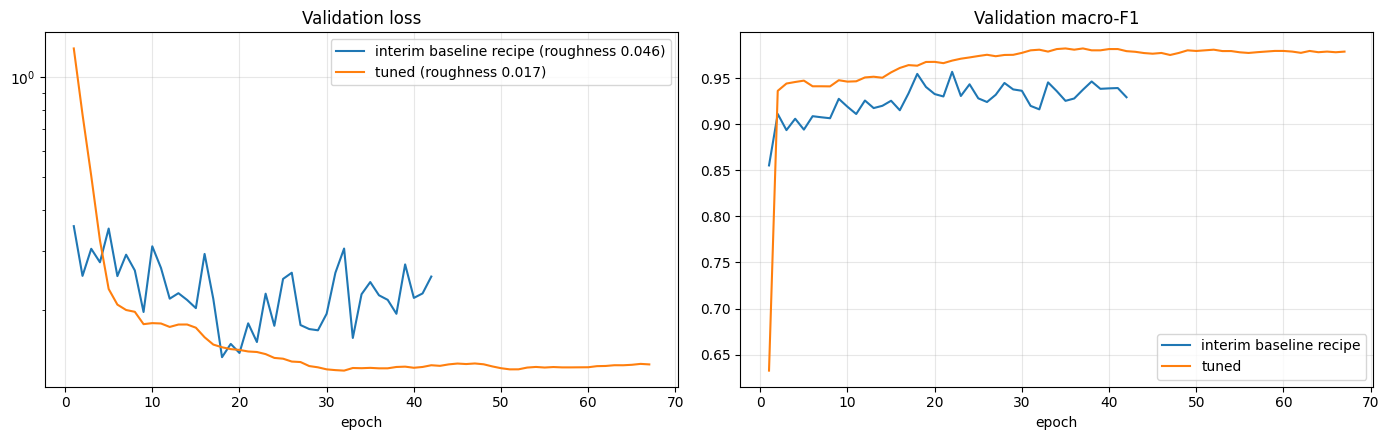

In [12]:
# ---------------------------------------------------------------- 11. Final model: load + learning curves
ckpt = torch.load(Path(best["run_dir"]) / "best.pt", map_location="cpu", weights_only=False)
final = HARTransformer(**ckpt["config"]).to(DEVICE)
final.load_state_dict(ckpt["state_dict"]); final.eval()
hist_final = pd.read_csv(Path(best["run_dir"]) / "history.csv")
hist_final.to_csv(OUT / "training_history_final.csv", index=False)
plot_history(hist_final, best["best_epoch"], f"Tuned Transformer - learning curves ({best['name']})",
             FIG_DIR / "learning_curves_final.png")

base_run = next((r for r in ablation if r["name"] == "abl_interim_baseline_recipe"), None)
if base_run:
    hb = pd.read_csv(Path(base_run["run_dir"]) / "history.csv")
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    ax[0].plot(hb.epoch, hb.val_loss, label=f"interim baseline recipe (roughness {roughness(hb.val_loss):.3f})")
    ax[0].plot(hist_final.epoch, hist_final.val_loss, label=f"tuned (roughness {roughness(hist_final.val_loss):.3f})")
    ax[0].set_yscale("log"); ax[0].set_title("Validation loss"); ax[0].legend()
    ax[1].plot(hb.epoch, hb.val_macro_f1, label="interim baseline recipe")
    ax[1].plot(hist_final.epoch, hist_final.val_macro_f1, label="tuned"); ax[1].set_title("Validation macro-F1")
    ax[1].legend()
    for a_ in ax:
        a_.set_xlabel("epoch"); a_.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(FIG_DIR / "baseline_vs_tuned_curves.png", dpi=150); plt.show()

                    precision    recall  f1-score   support

           WALKING     0.9855    0.9617    0.9735       496
  WALKING_UPSTAIRS     0.9800    0.9342    0.9565       471
WALKING_DOWNSTAIRS     0.9167    0.9952    0.9543       420
           SITTING     0.9621    0.8798    0.9191       491
          STANDING     0.9117    0.9699    0.9399       532
            LAYING     0.9890    1.0000    0.9944       537

          accuracy                         0.9569      2947
         macro avg     0.9575    0.9568    0.9563      2947
      weighted avg     0.9582    0.9569    0.9567      2947



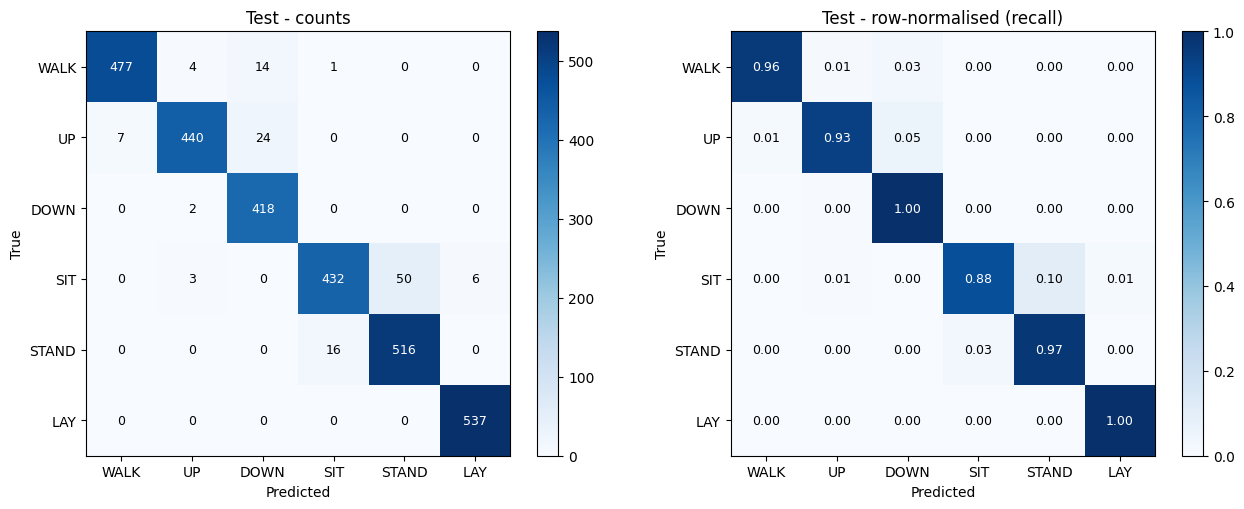

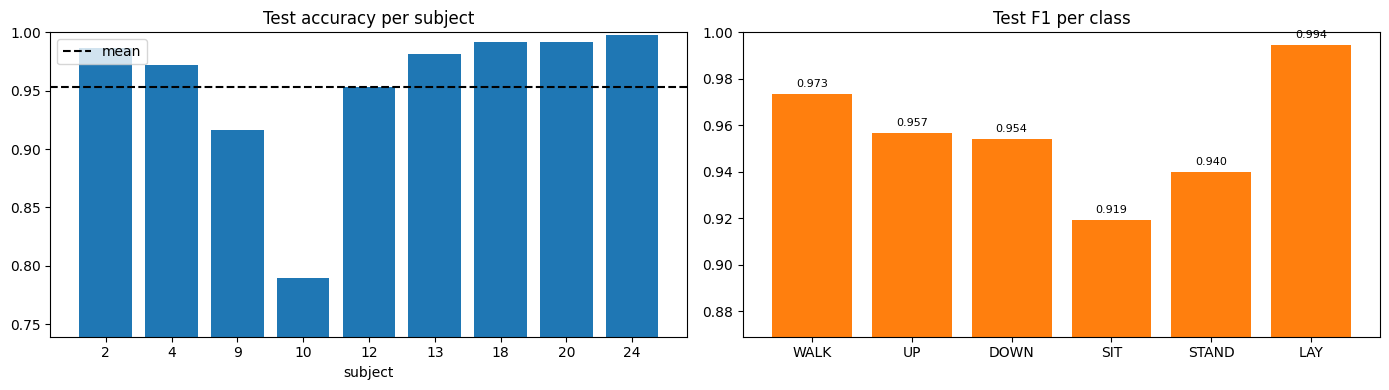

In [13]:
# ---------------------------------------------------------------- 12. THE single test evaluation
P_tr = predict_proba(final, data["X_train"])
P_va = predict_proba(final, data["X_val"])
P_te = predict_proba(final, data["X_test"])
y_te, s_te = data["y_test"], data["subj_test"]
pred_te = P_te.argmax(1)
np.savez_compressed(FINAL_DIR / "predictions.npz", P_train=P_tr, P_val=P_va, P_test=P_te,
                    y_test=y_te, subj_test=s_te)

from sklearn.metrics import classification_report
rep = classification_report(y_te, pred_te, target_names=hc.CLASS_NAMES, digits=4)
print(rep); open(OUT / "classification_report_test.txt", "w").write(rep)

hc.plot_confusion_matrix(y_te, pred_te, FIG_DIR / "confusion_matrix_test.png", "Test"); plt.show()
hc.plot_confusion_matrix(data["y_val"], P_va.argmax(1), FIG_DIR / "confusion_matrix_val.png", "Validation")
plt.close("all")

subj = hc.subject_stats(y_te, pred_te, s_te)["per_subject"]
pd.DataFrame({"subject": list(subj), "accuracy": list(subj.values())}) \
    .to_csv(OUT / "per_subject_accuracy_test.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar([str(s) for s in subj], list(subj.values()), color="tab:blue")
ax[0].axhline(np.mean(list(subj.values())), ls="--", c="k", label="mean"); ax[0].legend()
ax[0].set_ylim(min(subj.values()) - 0.05, 1); ax[0].set_title("Test accuracy per subject"); ax[0].set_xlabel("subject")
f1s = [hc.compute_metrics(y_te, P_te)[f"f1_{c}"] for c in hc.CLASS_NAMES]
ax[1].bar(["WALK", "UP", "DOWN", "SIT", "STAND", "LAY"], f1s, color="tab:orange")
ax[1].set_ylim(min(f1s) - 0.05, 1); ax[1].set_title("Test F1 per class")
for i, v in enumerate(f1s):
    ax[1].text(i, v + 0.003, f"{v:.3f}", ha="center", fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "per_subject_and_per_class.png", dpi=150); plt.show()

In [14]:
# ---------------------------------------------------------------- 13. Save model files + efficiency
weights_path = FINAL_DIR / "transformer_tuned_weights.pt"
torch.save(final.state_dict(), weights_path)
torch.save({"state_dict": final.state_dict(), "config": ckpt["config"], "scaler": scaler,
            "class_names": hc.CLASS_NAMES, "dataset_version": meta["dataset_version"]},
           FINAL_DIR / "transformer_tuned_checkpoint.pt")
json.dump(ckpt["config"], open(FINAL_DIR / "config.json", "w"), indent=2)

class RawInputWrapper(nn.Module):
    """Deployment wrapper: accepts RAW sensor windows (B, 128, 9) and returns class probabilities.
    The clipping + z-scoring from preprocessing is built into the graph."""
    def __init__(self, model, sc):
        super().__init__()
        self.model = model
        for k in ("clip_lo", "clip_hi", "mean", "std"):
            self.register_buffer(k, torch.tensor(sc[k], dtype=torch.float32))
    def forward(self, x):
        x = (torch.maximum(torch.minimum(x, self.clip_hi), self.clip_lo) - self.mean) / self.std
        return F.softmax(self.model(x), -1)

export_model = copy.deepcopy(final).cpu().eval()
export_model.set_sdpa(False)
wrapped = RawInputWrapper(export_model, scaler).eval()
try:
    ts = torch.jit.trace(wrapped, torch.randn(1, 128, 9))
    ts.save(str(FINAL_DIR / "transformer_tuned_raw_input.torchscript.pt"))
    print("TorchScript export OK")
except Exception as e:
    print("TorchScript export skipped:", e)
try:
    import importlib.util, subprocess
    if importlib.util.find_spec("onnx") is None:          # Colab does not ship onnx by default
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnx"], check=False)
    torch.onnx.export(wrapped, torch.randn(1, 128, 9), str(FINAL_DIR / "transformer_tuned_raw_input.onnx"),
                      input_names=["raw_window"], output_names=["probabilities"],
                      dynamic_axes={"raw_window": {0: "batch"}, "probabilities": {0: "batch"}}, dynamo=False)
    print("ONNX export OK")
except Exception as e:
    print("ONNX export skipped (optional):", type(e).__name__, str(e)[:120])

flop_model = copy.deepcopy(final).cpu().eval(); flop_model.set_sdpa(False)
efficiency = dict(
    params_total=hc.count_params(final),
    model_size_mb=hc.file_size_mb(weights_path),
    flops_per_window=hc.count_flops(flop_model, (1, 128, 9)),
    latency_ms_cpu_b1=hc.measure_latency(final, (1, 128, 9), "cpu"),
    latency_ms_gpu_b1=hc.measure_latency(final, (1, 128, 9), "cuda") if DEVICE == "cuda" else np.nan,
    throughput_gpu_wps=hc.measure_throughput(final, (128, 9), 256, "cuda") if DEVICE == "cuda" else np.nan,
    peak_gpu_mem_mb=best["peak_gpu_mem_mb"],
)
training = {k: best[k] for k in ("train_time_s", "epochs_trained", "best_epoch", "time_per_epoch_s")}
print(json.dumps(efficiency | training, indent=2, default=float))

/tmp/ipykernel_682/2632259978.py:28: TracerWarning: Iterating over a tensor might cause the trace to be incorrect. Passing a tensor of different shape won't change the number of iterations executed (and might lead to errors or silently give incorrect results).
  q, k, v = self.qkv(x).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
/tmp/ipykernel_682/2632259978.py:33: TracerWarning: Converting a tensor to a Python float might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  a = (q @ k.transpose(-2, -1)) / math.sqrt(D // self.h)


TorchScript export OK


/tmp/ipykernel_682/551175920.py:34: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(wrapped, torch.randn(1, 128, 9), str(FINAL_DIR / "transformer_tuned_raw_input.onnx"),


ONNX export OK
{
  "params_total": 95430,
  "model_size_mb": 0.3804044723510742,
  "flops_per_window": 14042368.0,
  "latency_ms_cpu_b1": 1.6482175466671833,
  "latency_ms_gpu_b1": 1.4361707666663883,
  "throughput_gpu_wps": 44548.838615017376,
  "peak_gpu_mem_mb": 178.18896484375,
  "train_time_s": 93.42217183113098,
  "epochs_trained": 67,
  "best_epoch": 37,
  "time_per_epoch_s": 1.3943607735989698
}


In [15]:
# ---------------------------------------------------------------- 14. Results CSV (metrics checklist)
c = BEST_CFG
notes = (f"Selected by 2-stage grid search on val macro-F1 ({len(stage_a) + len(stage_b)} configs) - run "
         f"{best['name']}. {c['stem']} stem (patch {c['patch'] if c['stem'] == 'conv' else 1}), d_model "
         f"{c['d_model']}, {c['n_layers']} pre-norm layers, {max(c['d_model'] // c['head_dim'], 1)} heads, FFN "
         f"{c['ff_mult']}x, {c['pool']} pooling, dropout {c['dropout']}, drop-path {c['drop_path']}; "
         f"{c['optimizer']} lr {c['lr']:g} wd {c['weight_decay']}, {c['schedule']} schedule "
         f"(warm-up {c['warmup_epochs']} ep), label smoothing {c['label_smoothing']}, EMA "
         f"{c['ema_decay'] if c['ema'] else 'off'}, aug '{c['aug']}' (on the fly), batch {c['batch_size']}, "
         f"AMP, grad-clip {c['grad_clip']}, early stop patience {c['patience']} / max {c['epochs']} ep. "
         f"FLOPs: torch.utils.flop_counter; CPU latency on 1 thread.")
row = hc.save_results(
    OUT / "transformer_results.csv",
    model_name="transformer", family="Transformer", owner=OWNER, input_representation="raw_9ch_128",
    run_tag="tuned",
    y_train=data["y_train"], proba_train=P_tr, y_val=data["y_val"], proba_val=P_va,
    y_test=y_te, proba_test=P_te, subj_test=s_te,
    efficiency=efficiency, training=training, seed=SEED, notes=notes, processed_dir=PROCESSED_DIR)

# Extra transformer-specific numbers (not part of the shared table)
extra = dict(selected_run=best["name"], val_loss_roughness=best["val_loss_roughness"],
             baseline_recipe_val_loss_roughness=base_run["val_loss_roughness"] if base_run else None,
             baseline_recipe_val_macro_f1=base_run["val_macro_f1"] if base_run else None,
             per_subject_test_accuracy=subj, n_configs_searched=len(stage_a) + len(stage_b),
             full_train=hc.compute_metrics(data["y_train"], P_tr), full_val=hc.compute_metrics(data["y_val"], P_va),
             full_test=hc.compute_metrics(y_te, P_te))
json.dump(extra, open(OUT / "metrics_full.json", "w"), indent=2, default=float)

pd.set_option("display.max_colwidth", 120)
pd.DataFrame([row]).T.rename(columns={0: "value"})

,value
model_name,transformer
family,Transformer
owner,K V Ananth Karantha
input_representation,raw_9ch_128
run_tag,tuned
dataset_version,uci-har-1683f8492733
test_accuracy,0.956905
test_macro_f1,0.956302
test_macro_precision,0.957485
test_macro_recall,0.956813


In [16]:
# ---------------------------------------------------------------- 15. Comparison with the interim baseline
interim = {"test_accuracy": 0.9284, "test_macro_f1": 0.9268, "test_cohen_kappa": 0.9140, "test_mcc": 0.9149,
           "sit_stand_confusion_rate": 0.086, "walking_variants_confusion_rate": 0.082,
           "gap_train_test_f1": 0.0706, "params_total": 76422, "latency_ms_cpu_b1": 3.01}
cmp_df = pd.DataFrame({"interim baseline": interim, "tuned": {k: row[k] for k in interim}})
cmp_df["change"] = cmp_df["tuned"] - cmp_df["interim baseline"]
cmp_df.to_csv(OUT / "baseline_vs_tuned_test.csv")
print(cmp_df.to_string(float_format=lambda v: f"{v:.4f}"))
print("\nAll outputs are in:", OUT)
for p in sorted(OUT.rglob("*")):
    if p.is_file() and "runs" not in p.parts:
        print("  ", p.relative_to(OUT))

                                 interim baseline      tuned     change
test_accuracy                              0.9284     0.9569     0.0285
test_macro_f1                              0.9268     0.9563     0.0295
test_cohen_kappa                           0.9140     0.9482     0.0342
test_mcc                                   0.9149     0.9485     0.0336
sit_stand_confusion_rate                   0.0860     0.0645    -0.0215
walking_variants_confusion_rate            0.0820     0.0368    -0.0452
gap_train_test_f1                          0.0706     0.0360    -0.0346
params_total                           76422.0000 95430.0000 19008.0000
latency_ms_cpu_b1                          3.0100     1.6482    -1.3618

All outputs are in: /content/drive/MyDrive/DL PROJ/Transformers
   Transformer_HAR_Tuned.ipynb
   ablation_results.csv
   baseline_vs_tuned_test.csv
   best_config.json
   classification_report_test.txt
   figures/ablation.png
   figures/baseline_vs_tuned_curves.png
   figures/c